# fine-tuning: Tracking von Training, Hyperparameter Optimierung (HPO), Registry

Benötigt das Routing der 77 Anliegen ein eigenes, fine-getuntes Modell, oder reicht ein kleiner Klassifikator auf den Embeddings?


In [6]:
# Ordner labs/ finden und zum Arbeitsordner machen: Das Paket common und die Daten liegen dort.
# Nötig, wenn der Kernel woanders startet (PyCharm, VS Code mit Arbeitsordner im Pack-Root, Quelle in labs/_src/).
import os, sys
from pathlib import Path
for _p in [Path.cwd(), Path.cwd() / "labs", *Path.cwd().parents]:
    if (_p / "common" / "__init__.py").exists():
        os.chdir(_p)
        sys.path.insert(0, str(_p))
        break
else:
    raise RuntimeError("Ordner labs/ nicht gefunden. Öffnen Sie das Notebook aus dem Ordner labs/ des Kursmaterials.")

import json
import logging
import time
from collections import Counter

import matplotlib.pyplot as plt
import mlflow
import optuna
from mlflow import MlflowClient
from sklearn.metrics import accuracy_score, f1_score

from common.paths import ARTIFACTS_DIR, LABS_DIR, offline

offline()  # vor dem ersten Laden eines Modells: die Labs laufen ohne Netzzugriff

from common import dvcrun
from common.data import dataset_hash, load_banking77
from common.finetune import (MIN_ACCURACY, SEED, TOLERANCE, baseline_logreg, cached_finetune, evaluate, finetune,
                             linear_probe, quality_gate, register_classifier, rule_gate, save_classifier,
                             split_fit_val)
from common.interactive import explore
from common.plotstyle import ACCENT, INK, LIGHT, MUTED, WARN, use_course_style
from common.tracking import CLASSIFIER_NAME, setup_mlflow

use_course_style()
optuna.logging.set_verbosity(optuna.logging.WARNING)
OUT = ARTIFACTS_DIR / "lab2"
PREPARED = OUT / "prepared"  # vorbereitete Läufe, die für die Live-Vorführung zu lange dauern
OUT.mkdir(parents=True, exist_ok=True)

logging.disable(logging.INFO)  # das erste Anlegen der Datenbank schreibt sonst viele Migrationszeilen
setup_mlflow("lab2")
logging.disable(logging.NOTSET)
client = MlflowClient()
DEMO_START = time.perf_counter()

train, test, intents = load_banking77()
fit_df, val_df = split_fit_val(train)  # 10 % stratifiziert als Validierung; das Testset bleibt bis zum Schluss liegen
DATA_HASH = dataset_hash(train, test)[:16]
print(f"Training {len(fit_df)}, Validierung {len(val_df)}, Test {len(test)}, Anliegen {len(intents)}, "
      f"Daten-Hash {DATA_HASH}")

Training 8993, Validierung 1000, Test 3076, Anliegen 77, Daten-Hash 3176e3ac9aef7185


In [7]:
with mlflow.start_run(run_name="baseline-minilm-logreg"):
    mlflow.log_params({"data_hash": DATA_HASH, "seed": SEED, "n_train": len(fit_df), "n_val": len(val_df)})
    baseline = baseline_logreg(fit_df, val_df, test, encoder_name="minilm-l6", use_cache=False)

print(f"Baseline auf dem Testset: Accuracy {baseline['test_accuracy']:.3f}, Macro-F1 {baseline['test_macro_f1']:.3f}")
print(f"Embeddings rechnen und Regression anpassen: {baseline['train_seconds']:.0f} s, davon Regression "
      f"{baseline['fit_seconds']:.1f} s; {baseline['texts_per_second']:.0f} Texte je Sekunde")

Baseline auf dem Testset: Accuracy 0.929, Macro-F1 0.929
Embeddings rechnen und Regression anpassen: 4 s, davon Regression 0.3 s; 2894 Texte je Sekunde


In [ ]:
DEFAULTS = {"learning_rate": 5e-5, "batch_size": 32}  # Empfehlung aus dem BERT-Paper, ohne Hyperparameter-Suche

with mlflow.start_run(run_name="bert-mini-default-1ep") as run:
    mlflow.log_param("data_hash", DATA_HASH)
    full_1ep = finetune(fit_df, val_df, intents, epochs=1, **DEFAULTS)
    full_1ep.update(evaluate(full_1ep["model"], full_1ep["tokenizer"], test))
    full_1ep["run_id"] = run.info.run_id

print(f"bert-mini, 1 Epoche, {DEFAULTS}: val_accuracy {full_1ep['val_accuracy']:.3f}, test_accuracy "
      f"{full_1ep['test_accuracy']:.3f}, Training {full_1ep['train_seconds']:.0f} s, "
      f"{format(full_1ep['trainable_parameters'], ',').replace(',', ' ')} trainierbare Parameter")

bert-mini, 1 Epoche, {'learning_rate': 5e-05, 'batch_size': 32}: val_accuracy 0.253, test_accuracy 0.235, Training 14 s, 11 190 349 trainierbare Parameter


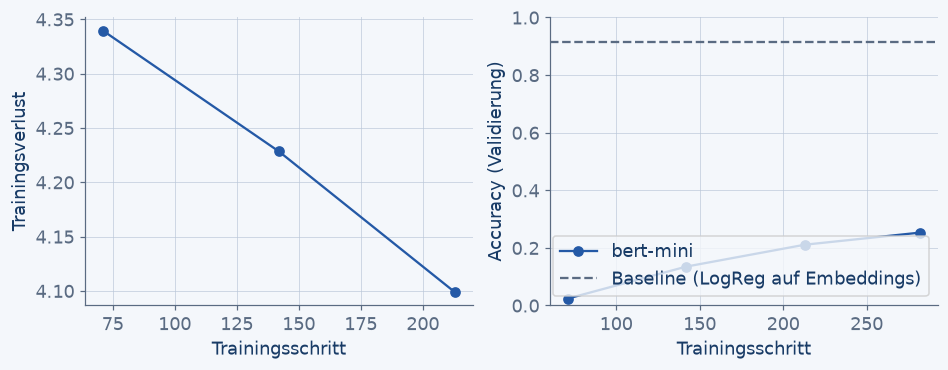

In [9]:
# Die Kurven kommen aus MLflow, nicht aus dem Notebook-Speicher: So sieht sie jede Person im Team.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, metric, label in ((ax1, "train_loss", "Trainingsverlust"), (ax2, "val_accuracy", "Accuracy (Validierung)")):
    points = client.get_metric_history(full_1ep["run_id"], metric)
    ax.plot([p.step for p in points], [p.value for p in points], marker="o", color=ACCENT, label="bert-mini")
    ax.set_xlabel("Trainingsschritt")
    ax.set_ylabel(label)
ax2.axhline(baseline["val_accuracy"], color=MUTED, linestyle="--", label="Baseline (LogReg auf Embeddings)")
ax2.set_ylim(0, 1)
ax2.legend(loc="lower right")
plt.show()

# Hyperparameter-Suche als Parent/Child Runs in MLFlow mit optuna

In [13]:
N_TRIALS, N_RANDOM = 12, 6


def objective(trial: optuna.Trial) -> float:
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])
    with mlflow.start_run(run_name=f"trial-{trial.number:02d}", nested=True):
        mlflow.log_param("data_hash", DATA_HASH)
        result = cached_finetune(PREPARED / f"hpo-trial-{trial.number:02d}", fit_df, val_df, intents,
                                 keep_model=False, learning_rate=learning_rate, batch_size=batch_size, epochs=1)
    trial.set_user_attr("prepared", result["from_cache"])
    return result["val_accuracy"]


with mlflow.start_run(run_name="hpo-bert-mini") as parent:
    mlflow.log_params({"data_hash": DATA_HASH, "n_trials": N_TRIALS, "sampler": f"TPESampler, {N_RANDOM} zufällig",
                       "epochs_per_trial": 1})
    sampler = optuna.samplers.TPESampler(seed=SEED, n_startup_trials=N_RANDOM)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=N_TRIALS)
    mlflow.log_params({f"best_{key}": value for key, value in study.best_params.items()})
    mlflow.log_metric("best_val_accuracy", study.best_value)
    mlflow.log_metric("gain_over_default", study.best_value - full_1ep["val_accuracy"])

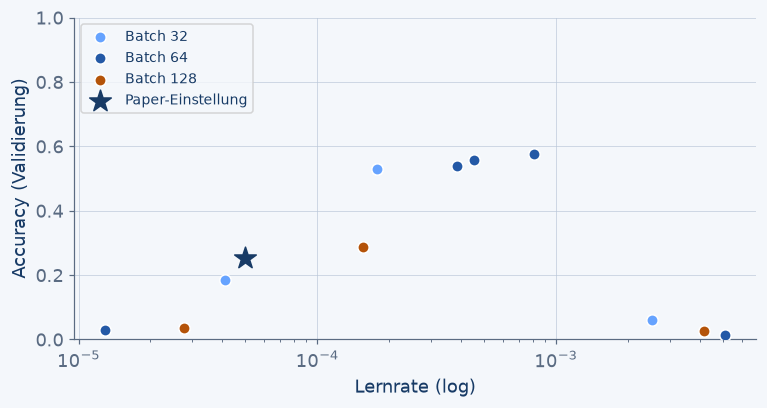

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for batch_size, color in ((32, LIGHT), (64, ACCENT), (128, WARN)):
    points = [(t.params["learning_rate"], t.value) for t in study.trials if t.params["batch_size"] == batch_size]
    if points:
        ax.scatter(*zip(*points), s=55, color=color, edgecolor="white", zorder=3, label=f"Batch {batch_size}")
ax.scatter([DEFAULTS["learning_rate"]], [full_1ep["val_accuracy"]], marker="*", s=220, color=INK, zorder=4,
           label="Paper-Einstellung")
ax.set_xscale("log")
ax.set_xlabel("Lernrate (log)")
ax.set_ylabel("Accuracy (Validierung)")
ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=9)
plt.show()

In [12]:
with mlflow.start_run(run_name="bert-mini-default-3ep"):
    mlflow.log_param("data_hash", DATA_HASH)
    default_3ep = cached_finetune(PREPARED / "bert-mini-default-3ep", fit_df, val_df, intents, epochs=3, **DEFAULTS)
    mlflow.set_tag("prepared", str(default_3ep["from_cache"]).lower())
    default_3ep.update(evaluate(default_3ep["model"], default_3ep["tokenizer"], test))

with mlflow.start_run(run_name="bert-mini-final-3ep") as final_run:
    mlflow.log_params({"data_hash": DATA_HASH, "hpo_parent_run_id": parent.info.run_id})
    final = cached_finetune(PREPARED / "bert-mini-final-3ep", fit_df, val_df, intents, epochs=3, **study.best_params)
    mlflow.set_tag("prepared", str(final["from_cache"]).lower())
    final.update(evaluate(final["model"], final["tokenizer"], test))

with mlflow.start_run(run_name="minilm-l6-finetuned-3ep"):
    mlflow.log_param("data_hash", DATA_HASH)
    minilm_ft = cached_finetune(PREPARED / "minilm-l6-finetuned-3ep", fit_df, val_df, intents, epochs=3,
                                learning_rate=1e-3, batch_size=64, base_model="minilm-l6")
    mlflow.set_tag("prepared", str(minilm_ft["from_cache"]).lower())
    minilm_ft.update(evaluate(minilm_ft["model"], minilm_ft["tokenizer"], test))

In [15]:
# Letzte Spalte: Durchsatz des zusätzlichen Modells im Anfragepfad (Testset, Batch 256, CPU)
print(f"{'':40s} {'Test-Accuracy':>13s} {'Macro-F1':>9s} {'Training':>9s} {'Texte je s, zusätzlich':>23s}")
for name, r in (("bert-mini, Paper-Einstellung, 3 Epochen", default_3ep), ("bert-mini, bester Trial, 3 Epochen", final),
                ("minilm-l6 fine-getunt, 3 Epochen", minilm_ft)):
    print(f"{name:40s} {r['test_accuracy']:13.3f} {r['test_macro_f1']:9.3f} {r['train_seconds']:8.0f} s "
          f"{r['texts_per_second']:23.0f}")
print(f"{'Baseline (LogReg auf Embeddings)':40s} {baseline['test_accuracy']:13.3f} {baseline['test_macro_f1']:9.3f} "
      f"{baseline['train_seconds']:8.0f} s {'nur die Regression':>23s}")

                                         Test-Accuracy  Macro-F1  Training  Texte je s, zusätzlich
bert-mini, Paper-Einstellung, 3 Epochen          0.558     0.502       41 s                    4615
bert-mini, bester Trial, 3 Epochen               0.873     0.873       31 s                    5431
minilm-l6 fine-getunt, 3 Epochen                 0.904     0.904       86 s                    2280
Baseline (LogReg auf Embeddings)                 0.929     0.929        4 s      nur die Regression
